# Quantitative Time-Series Deep Learning (60-Minute Lab)
**Objective:** Build, train, and backtest a Long Short-Term Memory (LSTM) neural network to forecast next-day asset returns without lookahead bias.

### Agenda
1. **00–10 min | Stationarity & Feature Engineering:** Why raw prices break neural networks, and how to construct stationary features.
2. **10–25 min | 3D Sliding-Window Tensors:** Reshaping 2D tabular time series into `(Samples, Sequence_Length, Features)` tensors without data leakage.
3. **25–40 min | LSTM Architecture:** Designing a PyTorch recurrent network with dropout regularization to combat low signal-to-noise ratios.
4. **40–50 min | Training Loop & Early Stopping:** Optimizing with Huber Loss and AdamW.
5. **50–60 min | Quantitative Backtesting:** Evaluating directional accuracy, equity curves, and annualized Sharpe Ratio.

### Environment Setup & Synthetic Market Data (00–10 Min)

Financial prices are non-stationary (their mean and variance drift over time). Feeding raw prices into an LSTM fails as soon as the asset trades outside its historical price range. Instead, we predict log returns ($r_t = \ln(P_t / P_{t-1})$) and use stationary technical indicators.Note: This cell generates realistic synthetic regime-switching market data out of the box so the notebook runs offline, with a one-line toggle to pull live Yahoo Finance data.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

# Set seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# --- 1. GENERATE REALISTIC REGIME-SWITCHING MARKET DATA ---
# (Optional: Uncomment below to use real data via yfinance)
import yfinance as yf
df = yf.download("SPY", start="2015-01-01", end="2025-01-01")[['Close', 'Volume']]

'''

n_days = 2500
dates = pd.date_range(start="2016-01-01", periods=n_days, freq="B")

# Simulate subtle momentum + mean-reversion + volatility clustering
returns = np.zeros(n_days)
volatility = np.ones(n_days) * 0.01
for t in range(2, n_days):
    volatility[t] = np.clip(0.9 * volatility[t-1] + 0.1 * abs(returns[t-1]) + np.random.normal(0, 0.0005), 0.005, 0.035)
    # Hidden non-linear signal: short-term momentum + medium-term mean reversion
    signal = 0.18 * returns[t-1] - 0.12 * returns[t-2] - 0.08 * np.tanh(sum(returns[max(0, t-10):t]) * 20)
    returns[t] = signal + np.random.normal(0, volatility[t])

prices = 100 * np.exp(np.cumsum(returns))
volume = np.random.lognormal(mean=15, sigma=0.4, size=n_days) * (1 + 15 * volatility)

df = pd.DataFrame({"Close": prices, "Volume": volume}, index=dates)
'''


# --- 2. STATIONARY FEATURE ENGINEERING ---
df["Log_Ret"] = np.log(df["Close"] / df["Close"].shift(1))
df["Ret_Lag1"] = df["Log_Ret"].shift(1)
df["Ret_Lag2"] = df["Log_Ret"].shift(2)
df["Rolling_Vol_10"] = df["Log_Ret"].rolling(10).std()
df["Momentum_5"] = df["Log_Ret"].rolling(5).sum()
df["Momentum_10"] = df["Log_Ret"].rolling(10).sum()
df["Vol_ZScore"] = (df["Volume"] - df["Volume"].rolling(20).mean()) / df["Volume"].rolling(20).std()

# Target: Next day's log return (shifted backward by 1 step)
df["Target_Next_Ret"] = df["Log_Ret"].shift(-1)
df.dropna(inplace=True)

feature_cols = ["Log_Ret", "Ret_Lag1", "Ret_Lag2", "Rolling_Vol_10", "Momentum_5", "Momentum_10", "Vol_ZScore"]
print(f"Dataset shape: {df.shape} | Features: {len(feature_cols)}")
df[feature_cols + ["Target_Next_Ret"]].head()

[*********************100%***********************]  1 of 1 completed

Using device: cuda
Dataset shape: (2496, 10) | Features: 7


Price,Log_Ret,Ret_Lag1,Ret_Lag2,Rolling_Vol_10,Momentum_5,Momentum_10,Vol_ZScore,Target_Next_Ret
Ticker,,,,,,,,
Date,,,,,,,,
2015-01-30,-0.012655,0.009201,-0.012907,0.010752,-0.027300,0.002158,1.088781,0.012308
2015-02-02,0.012308,-0.012655,0.009201,0.010659,-0.017331,0.001437,0.053952,0.014358
2015-02-03,0.014358,0.012308,-0.012655,0.011574,0.010305,0.013665,-0.988128,-0.003815
2015-02-04,-0.003815,0.014358,0.012308,0.011601,0.019397,0.004814,-0.624708,0.010044
2015-02-05,0.010044,-0.003815,0.014358,0.011038,0.020240,0.000097,-1.583580,-0.002769


### Chronological Split & 3D Sliding Windows (10–25 Min)

Crucial Rule in Financial ML: Never use random train_test_split or fit a StandardScaler on the full dataset. Doing so leaks future mean and variance into the past. Below, we split strictly by date, fit the scaler only on the training slice, and build 3D tensors of shape

In [4]:
# 1. Chronological Split (70% Train, 15% Validation, 15% Test)
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

# 2. Fit Scaler ONLY on Training Data to prevent lookahead leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_df[feature_cols])
X_val_scaled = scaler.transform(val_df[feature_cols])
X_test_scaled = scaler.transform(test_df[feature_cols])

# Scale targets by 100 (convert to percentage returns) for stable gradients
y_train_raw = train_df["Target_Next_Ret"].values * 100.0
y_val_raw = val_df["Target_Next_Ret"].values * 100.0
y_test_raw = test_df["Target_Next_Ret"].values * 100.0

# 3. Create 3D Sliding-Window Sequences: (Samples, Seq_Len, Features)
def create_sequences(features, targets, seq_len=20):
    X, y = [], []
    for i in range(seq_len, len(features)):
        # Window includes steps [i - seq_len ... i] to predict target at index i
        X.append(features[i - seq_len : i])
        y.append(targets[i - 1])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(1)

SEQ_LEN = 20  # 20 trading days (~1 month lookback)
X_train, y_train = create_sequences(X_train_scaled, y_train_raw, SEQ_LEN)
X_val, y_val = create_sequences(X_val_scaled, y_val_raw, SEQ_LEN)
X_test, y_test = create_sequences(X_test_scaled, y_test_raw, SEQ_LEN)

print(f"X_train tensor shape: {X_train.shape} -> (Samples, Lookback_Days, Features)")
print(f"X_val tensor shape:   {X_val.shape}")
print(f"X_test tensor shape:  {X_test.shape}")

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=False)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)

X_train tensor shape: torch.Size([1727, 20, 7]) -> (Samples, Lookback_Days, Features)
X_val tensor shape:   torch.Size([354, 20, 7])
X_test tensor shape:  torch.Size([355, 20, 7])


### LSTM Architecture in PyTorch (25–40 Min)

In financial time series, massive networks memorize noise. We keep the architecture compact (32 hidden units, 2 layers) and apply Dropout between recurrent layers and before the linear projection head.

In [5]:
class QuantLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, num_layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.layer_norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_dim)
        lstm_out, (h_n, c_n) = self.lstm(x)
        # Extract the output of the final time step in the sequence
        last_step = lstm_out[:, -1, :]
        out = self.layer_norm(last_step)
        out = self.dropout(out)
        return self.fc(out)

model = QuantLSTM(input_dim=len(feature_cols), hidden_dim=32, num_layers=2, dropout=0.3).to(device)
print(model)

QuantLSTM(
  (lstm): LSTM(7, 32, num_layers=2, batch_first=True, dropout=0.3)
  (layer_norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


### Training with Huber Loss & Weight Decay (40–50 Min)

Financial returns have "fat tails" (extreme market shocks). Using standard Mean Squared Error (MSE) causes the model to over-react to single outlier crash days. Huber Loss (SmoothL1Loss) acts like MSE for small errors and Mean Absolute Error (MAE) for extreme outliers.

In [6]:
criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

epochs = 35
train_losses, val_losses = [], []
best_val_loss = float("inf")
best_weights = None

for epoch in range(1, epochs + 1):
    # --- TRAIN ---
    model.train()
    batch_losses = []
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        preds = model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        # Gradient clipping prevents exploding gradients in RNNs
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_losses.append(loss.item())
    train_loss = np.mean(batch_losses)
    train_losses.append(train_loss)

    # --- VALIDATE ---
    model.eval()
    val_batch_losses = []
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            preds = model(X_batch)
            val_batch_losses.append(criterion(preds, y_batch).item())
    val_loss = np.mean(val_batch_losses)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

# Restore best validation weights
model.load_state_dict({k: v.to(device) for k, v in best_weights.items()})

Epoch 01/35 | Train Loss: 0.4349 | Val Loss: 0.6301
Epoch 05/35 | Train Loss: 0.3773 | Val Loss: 0.6394
Epoch 10/35 | Train Loss: 0.3738 | Val Loss: 0.6390
Epoch 15/35 | Train Loss: 0.3662 | Val Loss: 0.6499
Epoch 20/35 | Train Loss: 0.3625 | Val Loss: 0.6601
Epoch 25/35 | Train Loss: 0.3549 | Val Loss: 0.6493
Epoch 30/35 | Train Loss: 0.3552 | Val Loss: 0.6503
Epoch 35/35 | Train Loss: 0.3455 | Val Loss: 0.6629


<All keys matched successfully>

### Quantitative Backtest & Sharpe Ratio Evaluation (50–60 Min)

Low validation loss does not guarantee profitability. Quants evaluate models on Directional Hit Rate, Information Coefficient (IC) (rank correlation between predicted and realized returns), and the Annualized Sharpe Ratio after accounting for realistic position sizing.

$$\text{Sharpe Ratio} = \sqrt{252} \times \frac{\mathbb{E}[R_p]}{\sigma(R_p)}$$

=== OUT-OF-SAMPLE TEST METRICS ===
Directional Hit Rate:       58.03% (52-55% is strong in daily equities)
Information Coefficient:    0.0240 (Correlation of forecast vs realized)
LSTM Strategy Sharpe Ratio: 1.06
Buy & Hold Sharpe Ratio:    1.65


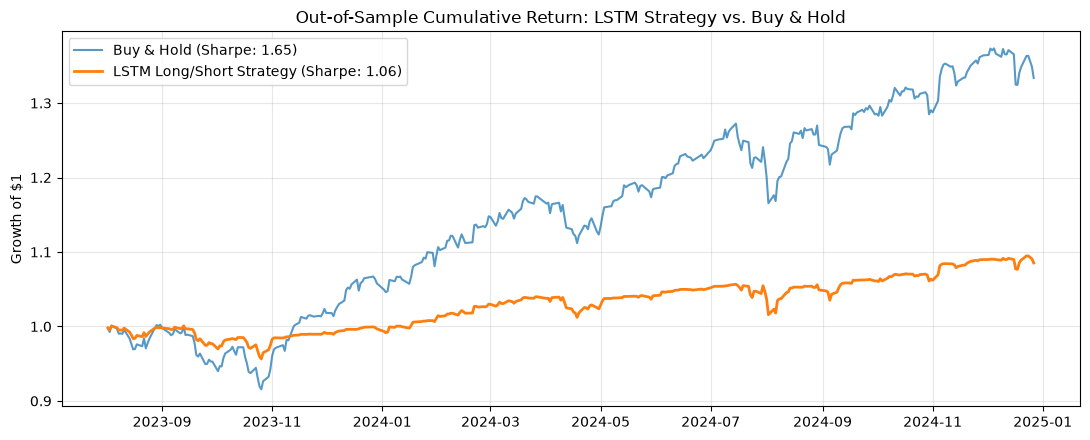

In [7]:
model.eval()
with torch.no_grad():
    preds_pct = model(X_test.to(device)).cpu().numpy().flatten()
    actual_pct = y_test.numpy().flatten()

# Convert back from percentage returns to raw log returns
preds_ret = preds_pct / 100.0
actual_ret = actual_pct / 100.0

# Strategy: Size position proportionally to model conviction (tanh-squashed forecast)
positions = np.tanh(preds_pct * 3.0)
# Subtract 10 basis point (0.1%) per turnover unit for transaction costs
turnover = np.abs(np.diff(positions, prepend=0))
strategy_ret = (positions * actual_ret) - (turnover * 0.001)

# Compute Quantitative Metrics
hit_rate = np.mean(np.sign(preds_ret) == np.sign(actual_ret)) * 100
ic = np.corrcoef(preds_ret, actual_ret)[0, 1]
sharpe_strategy = np.sqrt(252) * (np.mean(strategy_ret) / (np.std(strategy_ret) + 1e-8))
sharpe_buy_hold = np.sqrt(252) * (np.mean(actual_ret) / (np.std(actual_ret) + 1e-8))

print("=== OUT-OF-SAMPLE TEST METRICS ===")
print(f"Directional Hit Rate:       {hit_rate:.2f}% (52-55% is strong in daily equities)")
print(f"Information Coefficient:    {ic:.4f} (Correlation of forecast vs realized)")
print(f"LSTM Strategy Sharpe Ratio: {sharpe_strategy:.2f}")
print(f"Buy & Hold Sharpe Ratio:    {sharpe_buy_hold:.2f}")

# Plot Equity Curves
test_dates = test_df.index[SEQ_LEN - 1 : -1]
plt.figure(figsize=(11, 4.5))
plt.plot(test_dates, np.exp(np.cumsum(actual_ret)), label=f"Buy & Hold (Sharpe: {sharpe_buy_hold:.2f})", alpha=0.75)
plt.plot(test_dates, np.exp(np.cumsum(strategy_ret)), label=f"LSTM Long/Short Strategy (Sharpe: {sharpe_strategy:.2f})", linewidth=2)
plt.title("Out-of-Sample Cumulative Return: LSTM Strategy vs. Buy & Hold")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()